# DSC624 – Natural Language Processing and Large Language Models
## Assignment: Task 1 – LLM-Assisted Inventory Demand Forecasting and Route Optimization

**Name:** Parthvi Manoj  
**Roll number:** 2025EMAI10029  
**Dataset:** [DataCo SMART Supply Chain for Big Data Analysis](https://www.kaggle.com/datasets/shashwatwork/dataco-smart-supply-chain-for-big-data-analysis)  
**Runtime:** Google Colab, Tesla T4 GPU, seed 42

**Question:** Does adding LLM representations of product-category text to a numerical demand forecaster improve accuracy and how do the forecasts feed inventory and routing decisions?

| Part | Content |
|---|---|
| 1 | Data loading and audit |
| 2 | Weekly category demand panel |
| 3 | Features and chronological split |
| 4 | Numerical baselines (naive lag-1, Random Forest) |
| 5 | LLM category features (Qwen2.5-1.5B-Instruct, Phi-3.5-mini-instruct) |
| 6 | Forecast comparison |
| 7 | Robustness checks (seeds, random-vector control, no-category-ID ablation) |
| 8 | Inventory: reorder points and back-test |
| 9 | Routing: DBSCAN, nearest neighbour, 2-opt, OR-Tools |
| 10 | Summary |
| 11 | Results and discussion |

**Scope:** DataCo has no stock-on-hand, supplier lead times, depot locations, vehicle data or road distances, so the inventory and routing parts are simulations under stated assumptions.

In [1]:
# ortools is not preinstalled on Colab
!pip install -q ortools

import gc
import json
import random
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 140)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

OUTPUT_DIR = Path("/content/dsc624_final_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    torch.backends.cuda.matmul.allow_tf32 = True

PyTorch: 2.14.1+cu130 | device: cuda
GPU: Tesla T4


## 1. Data loading and audit

The orders file is downloaded with `kagglehub` (or read from `/kaggle/input` when running on Kaggle). Column names are normalised to snake_case.

In [2]:
import kagglehub

DATASET_PATH = Path("/kaggle/input/dataco-smart-supply-chain-for-big-data-analysis")
if not DATASET_PATH.exists():
    DATASET_PATH = Path(kagglehub.dataset_download(
        "shashwatwork/dataco-smart-supply-chain-for-big-data-analysis"
    ))

def find_csv(root, name_part):
    matches = [p for p in root.rglob("*.csv") if name_part.lower() in p.name.lower()]
    if not matches:
        raise FileNotFoundError(f"No CSV containing '{name_part}' under {root}")
    return matches[0]

def normalize_col(name):
    return re.sub(r"[^a-z0-9]+", "_", str(name).strip().lower()).strip("_")

orders_path = find_csv(DATASET_PATH, "DataCoSupplyChainDataset")
orders = pd.read_csv(orders_path, encoding="latin1", low_memory=False)
orders.columns = [normalize_col(c) for c in orders.columns]

required_columns = ["order_date_dateorders", "order_status", "order_item_quantity",
                    "category_name", "department_name", "product_name"]
missing = [c for c in required_columns if c not in orders.columns]
if missing:
    raise ValueError(f"Missing columns: {missing}")

orders["order_date_dateorders"] = pd.to_datetime(orders["order_date_dateorders"], errors="coerce")
orders["order_item_quantity"] = pd.to_numeric(orders["order_item_quantity"], errors="coerce")

print("Loaded:", orders_path.name, "| shape:", orders.shape)
print("Order dates:", orders["order_date_dateorders"].min(), "to", orders["order_date_dateorders"].max())
display(orders[required_columns].head())

Using Colab cache for faster access to the 'dataco-smart-supply-chain-for-big-data-analysis' dataset.
Loaded: DataCoSupplyChainDataset.csv | shape: (180519, 53)
Order dates: 2015-01-01 00:00:00 to 2018-01-31 23:38:00


,order_date_dateorders,order_status,order_item_quantity,category_name,department_name,product_name
0,2018-01-31 22:56:00,COMPLETE,1,Sporting Goods,Fitness,Smart watch
1,2018-01-13 12:27:00,PENDING,1,Sporting Goods,Fitness,Smart watch
2,2018-01-13 12:06:00,CLOSED,1,Sporting Goods,Fitness,Smart watch
3,2018-01-13 11:45:00,COMPLETE,1,Sporting Goods,Fitness,Smart watch
4,2018-01-13 11:24:00,PENDING_PAYMENT,1,Sporting Goods,Fitness,Smart watch


In [3]:
# Is there any free text to give the LLM? (product descriptions)
for col in [c for c in orders.columns if "description" in c]:
    text = orders[col].astype(str).str.strip().str.lower()
    non_empty = orders[col].notna() & ~text.isin(["", "nan", "none"])
    print(f"{col}: {int(non_empty.sum()):,} non-empty rows out of {len(orders):,}")

# Order status audit - cancelled, fraud and payment-review orders are not counted as demand
EXCLUDED_STATUSES = {"CANCELED", "SUSPECTED_FRAUD", "PAYMENT_REVIEW"}

status_audit = (
    orders.groupby("order_status", dropna=False)
    .agg(rows=("order_item_quantity", "size"),
         units=("order_item_quantity", "sum"),
         unique_orders=("order_id", "nunique"))
    .sort_values("rows", ascending=False)
)
display(status_audit)
status_audit.to_csv(OUTPUT_DIR / "order_status_audit.csv")

demand_df = orders.dropna(subset=["order_date_dateorders", "category_name", "order_item_quantity"])
demand_df = demand_df[demand_df["order_item_quantity"] >= 0]
demand_df = demand_df[~demand_df["order_status"].astype(str).str.upper().isin(EXCLUDED_STATUSES)].copy()

print("Rows kept:", len(demand_df), "| units:", demand_df["order_item_quantity"].sum(),
      "| categories:", demand_df["category_name"].nunique())

product_description: 0 non-empty rows out of 180,519


,rows,units,unique_orders
order_status,,,
COMPLETE,59491,126624,21716
PENDING_PAYMENT,39832,84736,14382
PROCESSING,21902,46623,7901
PENDING,20227,43196,7321
CLOSED,19616,41458,7249
ON_HOLD,9804,20845,3624
SUSPECTED_FRAUD,4062,8613,1488
CANCELED,3692,7875,1367
PAYMENT_REVIEW,1893,4109,704


Rows kept: 170872 | units: 363482 | categories: 50


## 2. Weekly category demand panel

Target = recorded order-item quantity per product category per week (weeks start on Monday). This is *recorded order demand*, not fulfilled sales.

- The week starting 29 Jan 2018 is dropped because the data ends on 31 Jan (partial week).
- Weeks with no orders, from a category's first week up to 22 Jan 2018, are set to 0. This is a modelling assumption: it cannot tell real zero demand apart from a discontinued category.

In [4]:
CATEGORY_COL = "category_name"
DATE_COL = "order_date_dateorders"
QTY_COL = "order_item_quantity"
LAST_COMPLETE_WEEK = pd.Timestamp("2018-01-22")

demand_df["week"] = demand_df[DATE_COL].dt.to_period("W").dt.start_time

weekly = (
    demand_df.groupby([CATEGORY_COL, "week"], as_index=False)[QTY_COL].sum()
    .rename(columns={QTY_COL: "demand"})
)
partial_week_units = weekly.loc[weekly["week"] > LAST_COMPLETE_WEEK, "demand"].sum()
weekly = weekly[weekly["week"] <= LAST_COMPLETE_WEEK]

all_weeks = pd.date_range(weekly["week"].min(), LAST_COMPLETE_WEEK, freq="W-MON")

# fill missing weeks with 0, starting from each category's first week
panel_parts = []
for category, group in weekly.groupby(CATEGORY_COL):
    weeks = all_weeks[all_weeks >= group["week"].min()]
    series = group.set_index("week")["demand"].reindex(weeks, fill_value=0.0)
    panel_parts.append(pd.DataFrame({CATEGORY_COL: category, "week": weeks, "demand": series.values}))

final_panel = (pd.concat(panel_parts, ignore_index=True)
               .sort_values([CATEGORY_COL, "week"]).reset_index(drop=True))

print("Panel:", final_panel.shape, "| categories:", final_panel[CATEGORY_COL].nunique(),
      "| weeks:", final_panel["week"].nunique())
print("Weeks:", final_panel["week"].min().date(), "to", final_panel["week"].max().date())
print("Total demand:", final_panel["demand"].sum(), "| zero category-weeks:", int((final_panel["demand"] == 0).sum()))
print("Units dropped with the partial last week:", partial_week_units)

display(
    final_panel.groupby(CATEGORY_COL)
    .agg(first_week=("week", "min"), weeks=("week", "nunique"),
         nonzero_weeks=("demand", lambda x: int((x > 0).sum())), total_demand=("demand", "sum"))
    .sort_values("total_demand", ascending=False).head(10)
)
final_panel.to_csv(OUTPUT_DIR / "category_week_panel.csv", index=False)

Panel: (4381, 3) | categories: 50 | weeks: 161
Weeks: 2014-12-29 to 2018-01-22
Total demand: 363288.0 | zero category-weeks: 974
Units dropped with the partial last week: 194


,first_week,weeks,nonzero_weeks,total_demand
category_name,,,,
Cleats,2014-12-29,161,145,69808.0
Women's Apparel,2014-12-29,161,145,59538.0
Indoor/Outdoor Games,2014-12-29,161,145,54682.0
Cardio Equipment,2014-12-29,161,145,35529.0
Shop By Sport,2014-12-29,161,145,30913.0
Men's Footwear,2014-12-29,161,145,21067.0
Fishing,2014-12-29,161,145,16419.0
Water Sports,2014-12-29,161,145,14727.0
Camping & Hiking,2014-12-29,161,145,13016.0


## 3. Features and chronological split

Features per category-week: demand lags (1, 2, 4, 8, 13 weeks), rolling mean/std over 4, 8 and 13 weeks (computed on the lag-1 series, so only past weeks are used) and calendar fields.

| Split | Weeks |
|---|---|
| Train | 5 Jan 2015 – 23 Jan 2017 |
| Validation | 30 Jan 2017 – 26 Jun 2017 (22 weeks) |
| Test | 3 Jul 2017 – 25 Sep 2017 (13 weeks) |

Only the 24 categories with history before the validation start are evaluated (26 of the 50 categories have no orders before then). Evaluation is one-step-ahead: lags in later test weeks use actual demand from earlier test weeks, but the models are not refitted during the test window.

In [5]:
model_data = final_panel.copy()
demand_by_cat = model_data.groupby(CATEGORY_COL)["demand"]

for lag in [1, 2, 4, 8, 13]:
    model_data[f"lag_{lag}"] = demand_by_cat.shift(lag)

previous = demand_by_cat.shift(1)
previous_by_cat = previous.groupby(model_data[CATEGORY_COL])
for window in [4, 8, 13]:
    model_data[f"rolling_mean_{window}"] = previous_by_cat.transform(
        lambda s: s.rolling(window, min_periods=1).mean())
    model_data[f"rolling_std_{window}"] = previous_by_cat.transform(
        lambda s: s.rolling(window, min_periods=2).std())

model_data["week_of_year"] = model_data["week"].dt.isocalendar().week.astype(int)
model_data["month"] = model_data["week"].dt.month
model_data["quarter"] = model_data["week"].dt.quarter
model_data["year"] = model_data["week"].dt.year
model_data["time_index"] = ((model_data["week"] - model_data["week"].min()).dt.days // 7).astype(int)
model_data = model_data.dropna(subset=["lag_1"]).copy()

TEST_START = pd.Timestamp("2017-07-03")
TEST_END = pd.Timestamp("2017-09-25")
VAL_START = TEST_START - pd.Timedelta(weeks=22)

warm_categories = set(final_panel.loc[final_panel["week"] < VAL_START, CATEGORY_COL])
stable = model_data[model_data[CATEGORY_COL].isin(warm_categories)]

train_df = stable[stable["week"] < VAL_START].copy()
validation_df = stable[(stable["week"] >= VAL_START) & (stable["week"] < TEST_START)].copy()
test_df = stable[(stable["week"] >= TEST_START) & (stable["week"] <= TEST_END)].copy()

split_summary = pd.DataFrame([
    {"split": name, "rows": len(df), "categories": df[CATEGORY_COL].nunique(),
     "weeks": df["week"].nunique(), "start": df["week"].min().date(),
     "end": df["week"].max().date(), "demand": df["demand"].sum()}
    for name, df in [("train", train_df), ("validation", validation_df), ("test", test_df)]
])
display(split_summary)

# sanity checks on the split
assert (len(train_df), len(validation_df), len(test_df)) == (2588, 528, 312)
assert train_df["week"].max() < validation_df["week"].min()
assert validation_df["week"].max() < test_df["week"].min()
assert set(test_df[CATEGORY_COL]) <= set(train_df[CATEGORY_COL])

model_data.to_csv(OUTPUT_DIR / "category_week_features.csv", index=False)
split_summary.to_csv(OUTPUT_DIR / "chronological_split_summary.csv", index=False)

,split,rows,categories,weeks,start,end,demand
0,train,2588,24,108,2015-01-05,2017-01-23,270158.0
1,validation,528,24,22,2017-01-30,2017-06-26,52562.0
2,test,312,24,13,2017-07-03,2017-09-25,29209.0


## 4. Numerical baselines

- **Naive:** forecast = last week's demand (lag-1).
- **Random Forest:** 400 trees, max depth 12, min 2 samples per leaf; median imputation for missing early lags; one-hot category ID. Predictions are clipped at 0.

Validation models are trained on the training split only; test models are refitted on train + validation.

Metrics: MAE and RMSE (units per category-week), WAPE = Σ|error| / Σ actual and sMAPE. sMAPE gives the maximum 200% to any non-zero forecast on a zero-demand week, so on this intermittent data it mostly measures how often a model predicts exactly zero. MAE, RMSE and WAPE are the main accuracy measures.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

NUMERIC_FEATURES = [
    "lag_1", "lag_2", "lag_4", "lag_8", "lag_13",
    "rolling_mean_4", "rolling_mean_8", "rolling_mean_13",
    "rolling_std_4", "rolling_std_8", "rolling_std_13",
    "week_of_year", "month", "quarter", "year", "time_index",
]
CATEGORICAL_FEATURES = [CATEGORY_COL]


def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)
    abs_err = np.abs(actual - predicted)
    denom = np.abs(actual) + np.abs(predicted)
    smape = np.divide(200 * abs_err, denom, out=np.zeros_like(denom), where=denom != 0)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "WAPE (%)": abs_err.sum() / np.abs(actual).sum() * 100,
        "sMAPE (%)": smape.mean(),
    }


def make_rf(numeric_cols, use_category=True, seed=SEED):
    blocks = [("num", SimpleImputer(strategy="median"), numeric_cols)]
    if use_category:
        blocks.append(("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES))
    rf = RandomForestRegressor(n_estimators=400, max_depth=12, min_samples_leaf=2,
                               random_state=seed, n_jobs=-1)
    return Pipeline([("prep", ColumnTransformer(blocks)), ("rf", rf)])


def fit_predict(train, evaluate, numeric_cols, use_category=True, seed=SEED):
    cols = numeric_cols + (CATEGORICAL_FEATURES if use_category else [])
    model = make_rf(numeric_cols, use_category, seed)
    model.fit(train[cols], train["demand"])
    return np.maximum(model.predict(evaluate[cols]), 0)


train_validation_df = pd.concat([train_df, validation_df], ignore_index=True)

val_preds = {
    "Naive (lag-1)": validation_df["lag_1"].clip(lower=0).to_numpy(),
    "Numerical RF": fit_predict(train_df, validation_df, NUMERIC_FEATURES),
}
test_preds = {
    "Naive (lag-1)": test_df["lag_1"].clip(lower=0).to_numpy(),
    "Numerical RF": fit_predict(train_validation_df, test_df, NUMERIC_FEATURES),
}

def results_table(actual, preds):
    return pd.DataFrame([{"Model": name, **calculate_metrics(actual, p)} for name, p in preds.items()])

print("Validation")
display(results_table(validation_df["demand"], val_preds).round(4))
print("Test")
display(results_table(test_df["demand"], test_preds).round(4))

Validation


,Model,MAE,RMSE,WAPE (%),sMAPE (%)
0,Naive (lag-1),14.0189,23.8771,14.0824,39.6693
1,Numerical RF,14.5522,21.8799,14.6181,58.7464


Test


,Model,MAE,RMSE,WAPE (%),sMAPE (%)
0,Naive (lag-1),11.7019,23.2859,12.4996,25.1788
1,Numerical RF,8.9279,16.3195,9.5365,79.4582


## 5. LLM category features

**Input text.** The description check in Part 1 shows `product_description` is empty for every row, so there is no real free text in DataCo. Instead, each category gets a short document built from catalogue fields - category name, department(s) and up to 40 product names - using **only orders before the validation start** (30 Jan 2017) to avoid look-ahead leakage.

The metadata is noisy: e.g. *Cardio Equipment* sits under *Footwear* with running-shoe products and *Electronics* is linked to two departments. That limits how much meaning an LLM can extract.

**Embedding.** Each document goes through a frozen model (no fine-tuning). Final hidden states are mean-pooled with the attention mask, giving one vector per category (1,536-d for Qwen, 3,072-d for Phi). PCA is fitted on the 24 category vectors and 4 components are kept. Both models run in fp16 on the T4.

Note: each category gets one fixed vector, while the Random Forest already sees the category ID and its demand history. So the LLM features can only help if the *similarity* between categories carries useful information - Part 7 tests this.

In [7]:
metadata_source = orders[orders[DATE_COL].notna() & (orders[DATE_COL] < VAL_START)].copy()
for col in ["category_name", "department_name", "product_name"]:
    metadata_source[col] = metadata_source[col].fillna("").astype(str).str.strip()

def unique_sorted(values):
    return sorted({v for v in values if v})

category_metadata = (
    metadata_source.groupby(CATEGORY_COL)
    .agg(departments=("department_name", unique_sorted),
         product_names=("product_name", unique_sorted))
    .reset_index()
)

def build_category_text(row):
    departments = ", ".join(row["departments"]) or "Unknown"
    products = ", ".join(row["product_names"][:40])
    return (f"Product category: {row[CATEGORY_COL]}. "
            f"Department(s): {departments}. "
            f"Products recorded in this category: {products}.")

category_metadata["category_text"] = category_metadata.apply(build_category_text, axis=1)
category_texts = category_metadata["category_text"].tolist()

# categories linked to more than one department
multi_dept = category_metadata[category_metadata["departments"].str.len() > 1]
print("Categories with more than one department:")
display(multi_dept[[CATEGORY_COL, "departments"]])

assert set(train_df[CATEGORY_COL]) <= set(category_metadata[CATEGORY_COL])
print("Metadata rows used:", len(metadata_source), "| cutoff:", VAL_START.date(),
      "| documents:", len(category_metadata))
display(category_metadata[[CATEGORY_COL, "category_text"]].head(8))
category_metadata.to_csv(OUTPUT_DIR / "prevalidation_category_text_metadata.csv", index=False)

Categories with more than one department:


,category_name,departments
6,Electronics,"[Footwear, Outdoors]"


Metadata rows used: 130081 | cutoff: 2017-01-30 | documents: 24


,category_name,category_text
0,Accessories,"Product category: Accessories. Department(s): Outdoors. Products recorded in this category: Team Golf New England Patriots Putter Grip, ..."
1,Baseball & Softball,Product category: Baseball & Softball. Department(s): Fitness. Products recorded in this category: adidas Kids' F5 Messi FG Soccer Cleat...
2,Boxing & MMA,Product category: Boxing & MMA. Department(s): Footwear. Products recorded in this category: Under Armour Women's Micro G Skulpt Running S.
3,Camping & Hiking,Product category: Camping & Hiking. Department(s): Fan Shop. Products recorded in this category: Diamondback Women's Serene Classic Comf...
4,Cardio Equipment,"Product category: Cardio Equipment. Department(s): Footwear. Products recorded in this category: Nike Men's Free 5.0+ Running Shoe, Nike..."
5,Cleats,Product category: Cleats. Department(s): Apparel. Products recorded in this category: Perfect Fitness Perfect Rip Deck.
6,Electronics,"Product category: Electronics. Department(s): Footwear, Outdoors. Products recorded in this category: Bridgestone e6 Straight Distance N..."
7,Fishing,Product category: Fishing. Department(s): Fan Shop. Products recorded in this category: Field & Stream Sportsman 16 Gun Fire Safe.


### 5.1 Qwen2.5-1.5B-Instruct

In [8]:
from tqdm.auto import tqdm
from transformers import AutoModel, AutoTokenizer

QWEN_MODEL_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
model_dtype = torch.float16 if device.type == "cuda" else torch.float32

tokenizer = AutoTokenizer.from_pretrained(QWEN_MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

qwen_model = AutoModel.from_pretrained(QWEN_MODEL_NAME, dtype=model_dtype,
                                       low_cpu_mem_usage=True).to(device)
qwen_model.eval()


def masked_mean_pool(last_hidden_state, attention_mask):
    # average over real tokens only (padding is masked out)
    mask = attention_mask.unsqueeze(-1).to(last_hidden_state.dtype)
    return (last_hidden_state * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)


def embed_texts(texts, batch_size=8, max_length=256):
    vectors = []
    for start in tqdm(range(0, len(texts), batch_size)):
        batch = tokenizer(texts[start:start + batch_size], return_tensors="pt",
                          padding=True, truncation=True, max_length=max_length)
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.inference_mode():
            if device.type == "cuda":
                with torch.autocast(device_type="cuda", dtype=torch.float16):
                    output = qwen_model(**batch)
            else:
                output = qwen_model(**batch)
            pooled = masked_mean_pool(output.last_hidden_state, batch["attention_mask"])
        vectors.append(pooled.float().cpu().numpy())
    return np.vstack(vectors)


qwen_embeddings = embed_texts(category_texts)
token_lengths = [len(tokenizer.encode(t)) for t in category_texts]
print("Qwen embeddings:", qwen_embeddings.shape)
print("Tokens per document: mean", round(np.mean(token_lengths), 2), "| max", max(token_lengths))

del qwen_model
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

Qwen embeddings: (24, 1536)
Tokens per document: mean 40.79 | max 133


### 5.2 Phi-3.5-mini-instruct

Loaded in fp16 (about 7.6 GB, fits on the T4 after Qwen is released). The final-layer hidden states are pooled the same way as for Qwen.

In [9]:
from transformers import AutoModelForCausalLM

PHI_MODEL_NAME = "microsoft/Phi-3.5-mini-instruct"
assert torch.cuda.is_available(), "Phi needs a GPU runtime"

phi_tokenizer = AutoTokenizer.from_pretrained(PHI_MODEL_NAME, trust_remote_code=True)
if phi_tokenizer.pad_token is None:
    phi_tokenizer.pad_token = phi_tokenizer.eos_token

phi_model = AutoModelForCausalLM.from_pretrained(PHI_MODEL_NAME, dtype=torch.float16,
                                                 device_map="auto", trust_remote_code=True)
phi_model.eval()


def embed_phi_texts(texts, batch_size=4, max_length=256):
    vectors = []
    input_device = phi_model.get_input_embeddings().weight.device
    for start in tqdm(range(0, len(texts), batch_size)):
        batch = phi_tokenizer(texts[start:start + batch_size], return_tensors="pt",
                              padding=True, truncation=True, max_length=max_length)
        batch = {k: v.to(input_device) for k, v in batch.items()}
        with torch.inference_mode():
            output = phi_model(**batch, output_hidden_states=True, use_cache=False)
            pooled = masked_mean_pool(output.hidden_states[-1], batch["attention_mask"])
        vectors.append(pooled.float().cpu().numpy())
    return np.vstack(vectors)


phi_embeddings = embed_phi_texts(category_texts)
print("Phi embeddings:", phi_embeddings.shape)

del phi_model
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

configuration_phi3.py:   0%|          | 0.00/11.2k [00:00<?, ?B/s]

[transformers] A new version of the following files was downloaded from https://huggingface.co/microsoft/Phi-3.5-mini-instruct:
- configuration_phi3.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.
/usr/local/lib/python3.13/dist-packages/transformers/configuration_utils.py:723: FutureWarning: `rope_scaling` is deprecated and will be removed in a future version. Set `rope_parameters` instead, with `rope_type` and `rope_theta` included.
  warnings.warn(
[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


tokenizer_config.json:   0%|          | 0.00/3.98k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.84M [00:00<?, ?B/s]

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

... (9 outputs left out)

generation_config.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

  0%|          | 0/6 [00:00<?, ?it/s]

[transformers] `use_return_dict` is deprecated! Use `return_dict` instead!
/usr/local/lib/python3.13/dist-packages/transformers/modeling_attn_mask_utils.py:71: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_attn_mask_utils.py:172: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is deprecated and will be removed in Transformers v5.10. Please use the new API in `transformers.masking_utils`.
  warnings.warn(DEPRECATION_MESSAGE, FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_attn_mask_utils.py:202: FutureWarning: The attention mask API under `transformers.modeling_attn_mask_utils` (`AttentionMaskConverter`) is de

Phi embeddings: (24, 3072)


### 5.3 PCA to 4 components per model

In [10]:
from sklearn.decomposition import PCA

def category_pca(embeddings, prefix, n_components=4):
    fit_rows = category_metadata[CATEGORY_COL].isin(set(train_df[CATEGORY_COL])).to_numpy()
    pca = PCA(n_components=n_components, random_state=SEED).fit(embeddings[fit_rows])
    columns = [f"{prefix}_pc_{i}" for i in range(1, n_components + 1)]
    table = pd.DataFrame(pca.transform(embeddings), columns=columns)
    table.insert(0, CATEGORY_COL, category_metadata[CATEGORY_COL].values)
    print(f"{prefix}: explained variance {np.round(pca.explained_variance_ratio_, 4)}, "
          f"total {pca.explained_variance_ratio_.sum():.4f}")
    return table, columns, pca

qwen_pca_df, QWEN_PCS, qwen_pca = category_pca(qwen_embeddings, "qwen")
phi_pca_df, PHI_PCS, phi_pca = category_pca(phi_embeddings, "phi")

def add_category_features(frame, features):
    if features is None:
        return frame
    return frame.merge(features, on=CATEGORY_COL, how="left", validate="many_to_one")

for df in [train_df, validation_df, test_df]:
    assert add_category_features(df, qwen_pca_df)[QWEN_PCS].notna().all().all()
    assert add_category_features(df, phi_pca_df)[PHI_PCS].notna().all().all()

qwen: explained variance [0.3157 0.168  0.0759 0.0568], total 0.6164
phi: explained variance [0.2296 0.1439 0.082  0.067 ], total 0.5225


## 6. Forecast comparison

Same splits, same Random Forest settings; the LLM models just get 4 extra columns.

In [11]:
llm_feature_sets = {
    "Qwen2.5-1.5B + RF": (qwen_pca_df, QWEN_PCS),
    "Phi-3.5-mini + RF": (phi_pca_df, PHI_PCS),
}

for name, (features, pcs) in llm_feature_sets.items():
    cols = NUMERIC_FEATURES + pcs
    val_preds[name] = fit_predict(add_category_features(train_df, features),
                                  add_category_features(validation_df, features), cols)
    test_preds[name] = fit_predict(add_category_features(train_validation_df, features),
                                   add_category_features(test_df, features), cols)

validation_results = results_table(validation_df["demand"], val_preds)
test_results = results_table(test_df["demand"], test_preds)

print("Validation (models trained on the training split)")
display(validation_results.round(4))
print("Test (models refitted on train + validation)")
display(test_results.round(4))

validation_results.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)
test_results.to_csv(OUTPUT_DIR / "test_model_comparison.csv", index=False)

predictions = test_df[["week", CATEGORY_COL, "demand"]].copy()
for name, pred in test_preds.items():
    predictions[name] = pred
predictions.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

Validation (models trained on the training split)


,Model,MAE,RMSE,WAPE (%),sMAPE (%)
0,Naive (lag-1),14.0189,23.8771,14.0824,39.6693
1,Numerical RF,14.5522,21.8799,14.6181,58.7464
2,Qwen2.5-1.5B + RF,14.9940,22.2622,15.0619,58.8028
3,Phi-3.5-mini + RF,14.6250,21.8587,14.6912,58.5641


Test (models refitted on train + validation)


,Model,MAE,RMSE,WAPE (%),sMAPE (%)
0,Naive (lag-1),11.7019,23.2859,12.4996,25.1788
1,Numerical RF,8.9279,16.3195,9.5365,79.4582
2,Qwen2.5-1.5B + RF,8.9815,16.4537,9.5938,45.7102
3,Phi-3.5-mini + RF,8.9402,16.3904,9.5496,74.8643


In [12]:
# Where does the sMAPE gap come from? Look at the 108 test weeks with zero demand.
y_test = test_df["demand"].to_numpy()
zero_week = y_test == 0

zero_rows = []
for name, pred in test_preds.items():
    zero_rows.append({
        "Model": name,
        "Non-zero forecast on zero week": int((zero_week & (pred > 0)).sum()),
        "Exact-zero forecast on zero week": int((zero_week & (pred == 0)).sum()),
        "Mean forecast, zero weeks": pred[zero_week].mean(),
        "Mean forecast, positive weeks": pred[~zero_week].mean(),
    })
zero_diagnostic = pd.DataFrame(zero_rows)
print("Zero-demand test weeks:", int(zero_week.sum()), "of", len(y_test))
display(zero_diagnostic.round(4))
zero_diagnostic.to_csv(OUTPUT_DIR / "zero_forecast_diagnostic.csv", index=False)

Zero-demand test weeks: 108 of 312


,Model,Non-zero forecast on zero week,Exact-zero forecast on zero week,"Mean forecast, zero weeks","Mean forecast, positive weeks"
0,Naive (lag-1),8,100,0.8426,143.2108
1,Numerical RF,96,12,1.6464,143.1659
2,Qwen2.5-1.5B + RF,44,64,1.6981,142.6059
3,Phi-3.5-mini + RF,90,18,1.7219,142.6134


## 7. Robustness checks

The differences above are small, so before reading anything into them:

1. **Seeds** – every RF variant is refitted with 5 seeds (mean ± std).
2. **Random-vector control** – 4 random numbers per category, scaled like the Qwen PCs. If this does as well as the LLM features, the *meaning* of the LLM vectors isn't what helps.
3. **No-category-ID ablation** – the one-hot category is removed, so category information can only come in through the extra vectors. This is the one setting where semantic similarity could add something.
4. **Week-block bootstrap** – 2,000 resamples of the 13 test weeks give a 95% CI for each MAE difference (negative = better than the reference).

In [13]:
ROBUST_SEEDS = [42, 7, 123, 2024, 31337]

rng = np.random.default_rng(SEED)
RAND_PCS = [f"rand_pc_{i}" for i in range(1, 5)]
random_control_df = pd.DataFrame(
    rng.normal(size=(len(qwen_pca_df), 4)) * qwen_pca_df[QWEN_PCS].std().to_numpy(),
    columns=RAND_PCS,
)
random_control_df.insert(0, CATEGORY_COL, qwen_pca_df[CATEGORY_COL].values)

# name -> (extra category features, their columns, use one-hot category ID)
variants = {
    "Numerical RF": (None, [], True),
    "Qwen + RF": (qwen_pca_df, QWEN_PCS, True),
    "Phi + RF": (phi_pca_df, PHI_PCS, True),
    "Random-vector control + RF": (random_control_df, RAND_PCS, True),
    "Numerical RF (no category ID)": (None, [], False),
    "Qwen + RF (no category ID)": (qwen_pca_df, QWEN_PCS, False),
    "Phi + RF (no category ID)": (phi_pca_df, PHI_PCS, False),
    "Random-vector control (no category ID)": (random_control_df, RAND_PCS, False),
}

seed_rows, seed_preds = [], {}
positive_week = y_test > 0
for name, (features, extra_cols, use_category) in variants.items():
    fit_frame = add_category_features(train_validation_df, features)
    eval_frame = add_category_features(test_df, features)
    for seed in ROBUST_SEEDS:
        pred = fit_predict(fit_frame, eval_frame, NUMERIC_FEATURES + extra_cols, use_category, seed)
        seed_preds[(name, seed)] = pred
        seed_rows.append({
            "Model": name, "seed": seed,
            **calculate_metrics(y_test, pred),
            "sMAPE actual>0 (%)": calculate_metrics(y_test[positive_week], pred[positive_week])["sMAPE (%)"],
            "Exact-zero forecasts on zero weeks": int((zero_week & (pred == 0)).sum()),
        })

seed_results = pd.DataFrame(seed_rows)
metric_cols = ["MAE", "RMSE", "WAPE (%)", "sMAPE (%)", "sMAPE actual>0 (%)",
               "Exact-zero forecasts on zero weeks"]
robust_summary = seed_results.groupby("Model", sort=False)[metric_cols].agg(["mean", "std"])
display(robust_summary.round(3))

MAE           RMSE        WAPE (%)  \
                                         mean    std    mean    std     mean   
Model                                                                          
Numerical RF                            9.015  0.057  16.498  0.115    9.629   
Qwen + RF                               9.088  0.065  16.657  0.120    9.707   
Phi + RF                                9.057  0.069  16.613  0.131    9.674   
Random-vector control + RF              9.046  0.057  16.521  0.132    9.662   
Numerical RF (no category ID)           9.256  0.049  16.988  0.107    9.887   
Qwen + RF (no category ID)              9.076  0.055  16.607  0.134    9.694   
Phi + RF (no category ID)               9.037  0.053  16.580  0.127    9.653   
Random-vector control (no category ID)  9.037  0.040  16.481  0.130    9.653   

                                              sMAPE (%)          \
                                          std      mean     std   
Model                                                             
Numerical RF                            0.061    66.712  19.866   
Qwen + RF                               0.070    67.118  17.411   
Phi + RF                                0.073    67.712  19.424   
Random-vector control + RF              0.061    60.996  25.286   
Numerical RF (no category ID)           0.052    70.147  18.753   
Qwen + RF (no category ID)              0.059    70.972  13.533   
Phi + RF (no category ID)               0.057    66.853  18.030   
Random-vector control (no category ID)  0.043    69.492  22.060   

                                       sMAPE actual>0 (%)         \
                                                     mean    std   
Model                                                              
Numerical RF                                       27.325  0.129   
Qwen + RF                                          26.573  0.194   
Phi + RF                                           26.305  0.139   
Random-vector control + RF                         27.602  0.226   
Numerical RF (no category ID)                      27.675  0.131   
Qwen + RF (no category ID)                         26.584  0.297   
Phi + RF (no category ID)                          26.364  0.212   
Random-vector control (no category ID)             27.655  0.250   

                                       Exact-zero forecasts on zero weeks  \
                                                                     mean   
Model                                                                       
Numerical RF                                                         31.8   
Qwen + RF                                                            30.4   
Phi + RF                                                             29.2   
Random-vector control + RF                                           41.0   
Numerical RF (no category ID)                                        26.8   
Qwen + RF (no category ID)                                           24.4   
Phi + RF (no category ID)                                            30.6   
Random-vector control (no category ID)                               27.8   

                                                
                                           std  
Model                                           
Numerical RF                            30.979  
Qwen + RF                               27.245  
Phi + RF                                30.310  
Random-vector control + RF              39.560  
Numerical RF (no category ID)           29.355  
Qwen + RF (no category ID)              21.173  
Phi + RF (no category ID)               28.041  
Random-vector control (no category ID)  34.572

In [14]:
# Week-block bootstrap for the MAE difference (candidate - reference)
test_weeks = test_df["week"].to_numpy()
rows_by_week = {w: np.where(test_weeks == w)[0] for w in np.unique(test_weeks)}
week_list = np.array(list(rows_by_week))

def seed_average(name):
    return np.mean([seed_preds[(name, s)] for s in ROBUST_SEEDS], axis=0)

def bootstrap_mae_diff(candidate, reference, n_boot=2000, seed=SEED):
    boot_rng = np.random.default_rng(seed)
    err_c = np.abs(y_test - seed_average(candidate))
    err_r = np.abs(y_test - seed_average(reference))
    diffs = []
    for _ in range(n_boot):
        idx = np.concatenate([rows_by_week[w] for w in
                              boot_rng.choice(week_list, size=len(week_list), replace=True)])
        diffs.append(err_c[idx].mean() - err_r[idx].mean())
    low, high = np.percentile(diffs, [2.5, 97.5])
    return err_c.mean() - err_r.mean(), low, high

pairs = [
    ("Qwen + RF", "Numerical RF"),
    ("Phi + RF", "Numerical RF"),
    ("Random-vector control + RF", "Numerical RF"),
    ("Qwen + RF (no category ID)", "Numerical RF (no category ID)"),
    ("Phi + RF (no category ID)", "Numerical RF (no category ID)"),
    ("Random-vector control (no category ID)", "Numerical RF (no category ID)"),
]
bootstrap_rows = []
for candidate, reference in pairs:
    diff, low, high = bootstrap_mae_diff(candidate, reference)
    bootstrap_rows.append({"Candidate": candidate, "Reference": reference, "Delta MAE": diff,
                           "95% CI low": low, "95% CI high": high,
                           "CI excludes 0": bool(low > 0 or high < 0)})
bootstrap_table = pd.DataFrame(bootstrap_rows)
display(bootstrap_table.round(3))

seed_results.to_csv(OUTPUT_DIR / "robustness_seed_runs.csv", index=False)
robust_summary.to_csv(OUTPUT_DIR / "robustness_summary.csv")
bootstrap_table.to_csv(OUTPUT_DIR / "robustness_bootstrap_mae.csv", index=False)

,Candidate,Reference,Delta MAE,95% CI low,95% CI high,CI excludes 0
0,Qwen + RF,Numerical RF,0.079,-0.233,0.381,False
1,Phi + RF,Numerical RF,0.049,-0.255,0.335,False
2,Random-vector control + RF,Numerical RF,0.035,-0.004,0.075,False
3,Qwen + RF (no category ID),Numerical RF (no category ID),-0.181,-0.458,0.090,False
4,Phi + RF (no category ID),Numerical RF (no category ID),-0.217,-0.474,0.022,False
5,Random-vector control (no category ID),Numerical RF (no category ID),-0.224,-0.602,0.104,False


## 8. Inventory planning

Assumptions (no real stock or lead-time data): lead time $L = 2$ weeks, 95% cycle service level ($z = 1.645$).

**8.1 Reorder points.** $SS = z\,\sigma_d\sqrt{L}$ and $ROP = L\,\bar{D}_{forecast} + SS$, where $\sigma_d$ is each category's weekly demand std over train + validation and $\bar{D}_{forecast}$ is the model's mean weekly forecast over the test window.

**8.2 Back-test.** The reorder-point totals don't show whether a better forecast gives better stock decisions, so each week $t$ the base stock is
$S_t = L\,\hat{y}_t + z\,\sigma_{err}\sqrt{L}$, where $\sigma_{err}$ is the per-category std of *that model's* validation errors (a more accurate model earns a smaller safety stock). $S_t$ is compared with actual demand over weeks $t$ and $t+1$. Cost = 1 × excess + 4 × shortage (assumed unit costs, only for comparing models).

In [15]:
LEAD_TIME_WEEKS = 2
SERVICE_LEVEL_Z = 1.645

model_keys = {"Naive (lag-1)": "naive", "Numerical RF": "numerical_rf",
              "Qwen2.5-1.5B + RF": "qwen_rf", "Phi-3.5-mini + RF": "phi_rf"}

demand_std = train_validation_df.groupby(CATEGORY_COL)["demand"].std().fillna(0)

inventory_plan = predictions.groupby(CATEGORY_COL)[list(model_keys)].mean()
inventory_plan.columns = [f"{model_keys[c]}_mean_weekly" for c in inventory_plan.columns]
inventory_plan["historical_std"] = demand_std
inventory_plan["safety_stock"] = SERVICE_LEVEL_Z * inventory_plan["historical_std"] * np.sqrt(LEAD_TIME_WEEKS)
for key in model_keys.values():
    inventory_plan[f"{key}_rop"] = (inventory_plan[f"{key}_mean_weekly"] * LEAD_TIME_WEEKS
                                    + inventory_plan["safety_stock"])

rop_totals = pd.DataFrame({
    "Model": list(model_keys),
    "Total reorder point (units)": [inventory_plan[f"{k}_rop"].sum() for k in model_keys.values()],
})
display(rop_totals.round(2))
display(inventory_plan.filter(regex="historical_std|safety_stock|_rop$").round(2).head(12))

inventory_plan.to_csv(OUTPUT_DIR / "inventory_reorder_points.csv")
rop_totals.to_csv(OUTPUT_DIR / "inventory_rop_totals.csv", index=False)

,Model,Total reorder point (units)
0,Naive (lag-1),5357.93
1,Numerical RF,5369.88
2,Qwen2.5-1.5B + RF,5353.16
3,Phi-3.5-mini + RF,5353.80


,historical_std,safety_stock,naive_rop,numerical_rf_rop,qwen_rf_rop,phi_rf_rop
category_name,,,,,,
Accessories,15.89,36.97,36.97,36.98,36.97,37.04
Baseball & Softball,7.87,18.32,23.39,32.12,29.37,27.89
Boxing & MMA,6.43,14.95,50.95,49.61,46.57,46.66
Camping & Hiking,8.38,19.50,198.27,204.53,204.04,204.31
Cardio Equipment,30.59,71.15,549.46,545.30,533.53,533.67
Cleats,39.62,92.16,1058.93,1007.61,1007.99,1007.63
Electronics,25.09,58.37,58.37,58.39,58.43,58.40
Fishing,11.04,25.68,262.60,252.90,251.69,252.35
Fitness Accessories,5.24,12.20,12.20,12.21,12.20,12.21


In [16]:
HOLDING_COST, SHORTAGE_COST = 1.0, 4.0

# per-category std of each model's validation errors
val_errors = validation_df[[CATEGORY_COL]].copy()
for name in model_keys:
    val_errors[name] = validation_df["demand"].to_numpy() - val_preds[name]
error_std = val_errors.groupby(CATEGORY_COL).std().fillna(0)

backtest = predictions.sort_values([CATEGORY_COL, "week"]).reset_index(drop=True)
backtest["lead_time_demand"] = backtest["demand"] + backtest.groupby(CATEGORY_COL)["demand"].shift(-1)
backtest = backtest.dropna(subset=["lead_time_demand"])  # last test week has no week t+1

backtest_rows = []
for name in model_keys:
    sigma = backtest[CATEGORY_COL].map(error_std[name])
    base_stock = LEAD_TIME_WEEKS * backtest[name] + SERVICE_LEVEL_Z * sigma * np.sqrt(LEAD_TIME_WEEKS)
    excess = np.maximum(base_stock - backtest["lead_time_demand"], 0)
    shortage = np.maximum(backtest["lead_time_demand"] - base_stock, 0)
    backtest_rows.append({
        "Forecast model": name,
        "Service level achieved (%)": 100 * (shortage == 0).mean(),
        "Mean excess / category-week": excess.mean(),
        "Mean shortage / category-week": shortage.mean(),
        "Total cost (h=1, p=4)": (HOLDING_COST * excess + SHORTAGE_COST * shortage).sum(),
    })
inventory_backtest = pd.DataFrame(backtest_rows)
print("Category-weeks evaluated:", len(backtest), "| target service level: 95%")
display(inventory_backtest.round(2))
inventory_backtest.to_csv(OUTPUT_DIR / "inventory_backtest.csv", index=False)

Category-weeks evaluated: 288 | target service level: 95%


,Forecast model,Service level achieved (%),Mean excess / category-week,Mean shortage / category-week,"Total cost (h=1, p=4)"
0,Naive (lag-1),94.44,44.99,1.24,14390.25
1,Numerical RF,97.22,40.03,0.38,11971.18
2,Qwen2.5-1.5B + RF,96.18,39.77,0.43,11946.47
3,Phi-3.5-mini + RF,96.18,39.36,0.43,11834.03


## 9. Routing

DBSCAN (haversine, ε = 10 km, min 2 points) groups the unique latitude/longitude pairs. From the largest cluster, 20 locations within 10 km of the centroid are sampled (seed 42); their centroid is used as the depot. A nearest-neighbour tour is improved with 2-opt.

Notes:
- DataCo's field description lists these coordinates as **store** locations, so they only stand in for delivery points here.
- Distances are straight-line (haversine), not road distances; one vehicle, no capacity or time windows.

In [17]:
from sklearn.cluster import DBSCAN

EARTH_RADIUS_KM = 6371.0

coordinates = orders[["latitude", "longitude"]].apply(pd.to_numeric, errors="coerce").dropna()
coordinates = coordinates[coordinates["latitude"].between(-90, 90) &
                          coordinates["longitude"].between(-180, 180)]
coordinates = coordinates.drop_duplicates().reset_index(drop=True)
print("Unique coordinate pairs:", len(coordinates))

dbscan = DBSCAN(eps=10 / EARTH_RADIUS_KM, min_samples=2, metric="haversine")
coordinates["cluster"] = dbscan.fit_predict(np.radians(coordinates[["latitude", "longitude"]].to_numpy()))

cluster_summary = (
    coordinates[coordinates["cluster"] != -1].groupby("cluster")
    .agg(locations=("latitude", "size"), centroid_lat=("latitude", "mean"), centroid_lon=("longitude", "mean"))
    .reset_index().sort_values("locations", ascending=False)
)
display(cluster_summary.head(10))
print("Noise points:", int((coordinates["cluster"] == -1).sum()))

Unique coordinate pairs: 11835


,cluster,locations,centroid_lat,centroid_lon
21,21,4221,18.249675,-66.370495
0,0,3269,18.251830,-66.037947
2,2,578,33.963716,-118.033085
6,6,312,40.726580,-73.920934
10,10,254,41.883904,-87.778557
4,4,112,25.894067,-80.227844
16,16,81,32.921277,-96.794879
120,120,77,36.114209,-115.146717
39,39,76,33.459257,-112.018756
26,26,76,29.738064,-95.486814


Noise points: 264


In [18]:
from ortools.constraint_solver import pywrapcp, routing_enums_pb2


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = np.radians([lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(a))


def distance_matrix_km(points):
    n = len(points)
    dm = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            dm[i, j] = haversine_km(points[i, 0], points[i, 1], points[j, 0], points[j, 1])
    return dm


def route_length(route, dm):
    return sum(dm[route[i], route[i + 1]] for i in range(len(route) - 1))


def nearest_neighbour_route(dm):
    route, unvisited = [0], set(range(1, len(dm)))
    while unvisited:
        nxt = min(unvisited, key=lambda stop: dm[route[-1], stop])
        route.append(nxt)
        unvisited.remove(nxt)
    return route + [0]


def two_opt(route, dm):
    # first-improvement 2-opt; depot stays at both ends
    best, best_len = route[:], route_length(route, dm)
    improved = True
    while improved:
        improved = False
        for i in range(1, len(best) - 2):
            for j in range(i + 1, len(best) - 1):
                candidate = best[:i] + best[i:j + 1][::-1] + best[j + 1:]
                cand_len = route_length(candidate, dm)
                if cand_len < best_len - 1e-9:
                    best, best_len, improved = candidate, cand_len, True
                    break
            if improved:
                break
    return best, best_len


def ortools_tsp(dm, time_limit_s=10):
    metres = np.rint(dm * 1000).astype(int)
    manager = pywrapcp.RoutingIndexManager(len(metres), 1, 0)
    routing = pywrapcp.RoutingModel(manager)
    transit = routing.RegisterTransitCallback(
        lambda i, j: int(metres[manager.IndexToNode(i), manager.IndexToNode(j)]))
    routing.SetArcCostEvaluatorOfAllVehicles(transit)
    params = pywrapcp.DefaultRoutingSearchParameters()
    params.first_solution_strategy = routing_enums_pb2.FirstSolutionStrategy.PATH_CHEAPEST_ARC
    params.local_search_metaheuristic = routing_enums_pb2.LocalSearchMetaheuristic.GUIDED_LOCAL_SEARCH
    params.time_limit.seconds = time_limit_s
    solution = routing.SolveWithParameters(params)
    index, route = routing.Start(0), []
    while not routing.IsEnd(index):
        route.append(manager.IndexToNode(index))
        index = solution.Value(routing.NextVar(index))
    return route + [0], route_length(route + [0], dm)


def spread_km(points):
    ns = haversine_km(points[:, 0].min(), points[:, 1].mean(), points[:, 0].max(), points[:, 1].mean())
    ew = haversine_km(points[:, 0].mean(), points[:, 1].min(), points[:, 0].mean(), points[:, 1].max())
    return ns, ew


def sample_stops(cluster_id, n_stops=20, radius_km=10):
    members = coordinates.loc[coordinates["cluster"] == cluster_id, ["latitude", "longitude"]]
    n = len(members)
    dist = haversine_km(np.full(n, members["latitude"].mean()), np.full(n, members["longitude"].mean()),
                        members["latitude"].to_numpy(), members["longitude"].to_numpy())
    candidates = members[dist <= radius_km]
    if len(candidates) < n_stops:
        return None
    stops = candidates.sample(n=n_stops, random_state=SEED).to_numpy()
    return np.vstack([stops.mean(axis=0), stops])  # row 0 = depot (centroid)


def compare_routes(points):
    dm = distance_matrix_km(points)
    nn = nearest_neighbour_route(dm)
    opt, opt_len = two_opt(nn, dm)
    ort, ort_len = ortools_tsp(dm)
    return {"Nearest neighbour (km)": route_length(nn, dm), "NN + 2-opt (km)": opt_len,
            "OR-Tools GLS (km)": ort_len,
            # any closed tour visits the two farthest stops, so it is at least 2x their distance
            "Lower bound (km)": 2 * dm.max()}, nn, opt


def plot_route(route, points, title):
    ordered = points[np.array(route)]
    plt.figure(figsize=(7, 5))
    plt.plot(ordered[:, 1], ordered[:, 0], marker="o", linewidth=1.2)
    plt.scatter(points[0, 1], points[0, 0], marker="*", s=180, label="Depot (assumed)", zorder=3)
    for idx, (lat, lon) in enumerate(points[1:], start=1):
        plt.annotate(str(idx), (lon, lat), fontsize=7)
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

Cluster 21: stops spread 10.11 km north-south, 14 m east-west


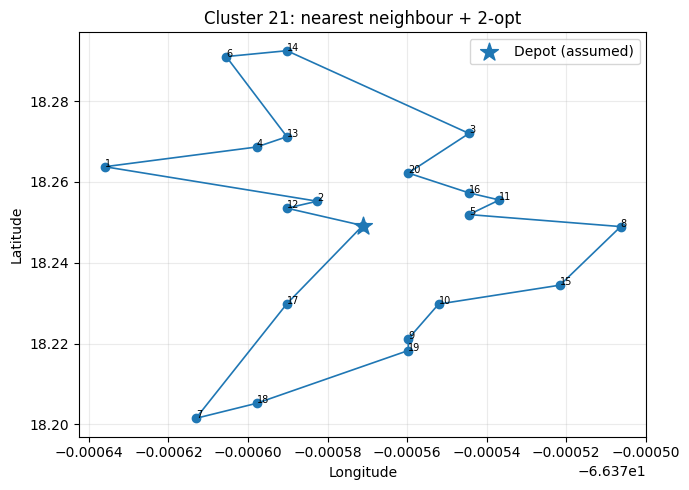

In [19]:
# Original experiment: largest cluster
largest_cluster = int(cluster_summary.iloc[0]["cluster"])
line_points = sample_stops(largest_cluster)
ns_km, ew_km = spread_km(line_points[1:])
print(f"Cluster {largest_cluster}: stops spread {ns_km:.2f} km north-south, {ew_km * 1000:.0f} m east-west")

line_result, line_nn, line_opt = compare_routes(line_points)
plot_route(line_opt, line_points, f"Cluster {largest_cluster}: nearest neighbour + 2-opt")

The stops in the largest cluster lie almost on one north–south line, so the shortest closed tour is just out-and-back and 2-opt can hardly improve on nearest neighbour. To get a meaningful comparison, the experiment is repeated on the largest cluster whose 20-stop sample spreads at least 2 km in both directions.

Cluster 2: 17.2 km x 15.2 km


,Sample,Nearest neighbour (km),NN + 2-opt (km),OR-Tools GLS (km),Lower bound (km),2-opt saving vs NN (%),OR-Tools saving vs NN (%)
0,Cluster 21 (line-shaped),20.284,20.226,20.226,20.226,0.287,0.286
1,Cluster 2 (2-D),69.791,68.336,66.557,36.117,2.085,4.634


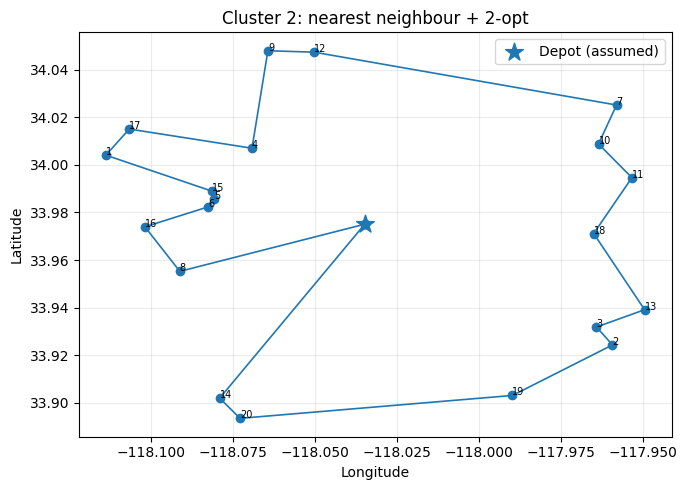

In [20]:
MIN_SPREAD_KM = 2.0
for cluster_id in cluster_summary["cluster"].astype(int):
    points_2d = sample_stops(cluster_id)
    if points_2d is not None and min(spread_km(points_2d[1:])) >= MIN_SPREAD_KM:
        break
else:
    raise ValueError("No cluster with a 2-D spread found")

ns_km, ew_km = spread_km(points_2d[1:])
print(f"Cluster {cluster_id}: {ns_km:.1f} km x {ew_km:.1f} km")
result_2d, nn_2d, opt_2d = compare_routes(points_2d)

route_results = pd.DataFrame([
    {"Sample": f"Cluster {largest_cluster} (line-shaped)", **line_result},
    {"Sample": f"Cluster {cluster_id} (2-D)", **result_2d},
])
route_results["2-opt saving vs NN (%)"] = 100 * (1 - route_results["NN + 2-opt (km)"] / route_results["Nearest neighbour (km)"])
route_results["OR-Tools saving vs NN (%)"] = 100 * (1 - route_results["OR-Tools GLS (km)"] / route_results["Nearest neighbour (km)"])
display(route_results.round(3))
route_results.to_csv(OUTPUT_DIR / "route_comparison.csv", index=False)

plot_route(opt_2d, points_2d, f"Cluster {cluster_id}: nearest neighbour + 2-opt")

## 10. Summary

In [21]:
summary = {
    "dataset": "DataCo SMART Supply Chain for Big Data Analysis",
    "forecast_grain": "category-week",
    "demand_proxy": "order_item_quantity excluding CANCELED, SUSPECTED_FRAUD, PAYMENT_REVIEW",
    "validation": f"{validation_df['week'].min().date()} to {validation_df['week'].max().date()}",
    "test": f"{test_df['week'].min().date()} to {test_df['week'].max().date()}",
    "test_rows": len(test_df),
    "categories": test_df[CATEGORY_COL].nunique(),
    "qwen": {"model": QWEN_MODEL_NAME, "dims": qwen_embeddings.shape[1],
             "pca_variance": float(qwen_pca.explained_variance_ratio_.sum())},
    "phi": {"model": PHI_MODEL_NAME, "dims": phi_embeddings.shape[1],
            "pca_variance": float(phi_pca.explained_variance_ratio_.sum())},
    "test_results": test_results.round(4).to_dict(orient="records"),
    "bootstrap_mae": bootstrap_table.round(4).to_dict(orient="records"),
    "inventory_backtest": inventory_backtest.round(2).to_dict(orient="records"),
    "routes": route_results.round(3).to_dict(orient="records"),
    "assumptions": {"lead_time_weeks": LEAD_TIME_WEEKS, "service_level": 0.95,
                    "holding_cost": HOLDING_COST, "shortage_cost": SHORTAGE_COST},
}
with open(OUTPUT_DIR / "final_experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

display(test_results.round(4))
display(bootstrap_table.round(3))
display(inventory_backtest.round(2))
display(route_results.round(3))

print("\nSaved files:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print(f"  {path.name:45s} {path.stat().st_size / 1024:7.1f} KB")

,Model,MAE,RMSE,WAPE (%),sMAPE (%)
0,Naive (lag-1),11.7019,23.2859,12.4996,25.1788
1,Numerical RF,8.9279,16.3195,9.5365,79.4582
2,Qwen2.5-1.5B + RF,8.9815,16.4537,9.5938,45.7102
3,Phi-3.5-mini + RF,8.9402,16.3904,9.5496,74.8643


,Candidate,Reference,Delta MAE,95% CI low,95% CI high,CI excludes 0
0,Qwen + RF,Numerical RF,0.079,-0.233,0.381,False
1,Phi + RF,Numerical RF,0.049,-0.255,0.335,False
2,Random-vector control + RF,Numerical RF,0.035,-0.004,0.075,False
3,Qwen + RF (no category ID),Numerical RF (no category ID),-0.181,-0.458,0.090,False
4,Phi + RF (no category ID),Numerical RF (no category ID),-0.217,-0.474,0.022,False
5,Random-vector control (no category ID),Numerical RF (no category ID),-0.224,-0.602,0.104,False


,Forecast model,Service level achieved (%),Mean excess / category-week,Mean shortage / category-week,"Total cost (h=1, p=4)"
0,Naive (lag-1),94.44,44.99,1.24,14390.25
1,Numerical RF,97.22,40.03,0.38,11971.18
2,Qwen2.5-1.5B + RF,96.18,39.77,0.43,11946.47
3,Phi-3.5-mini + RF,96.18,39.36,0.43,11834.03


,Sample,Nearest neighbour (km),NN + 2-opt (km),OR-Tools GLS (km),Lower bound (km),2-opt saving vs NN (%),OR-Tools saving vs NN (%)
0,Cluster 21 (line-shaped),20.284,20.226,20.226,20.226,0.287,0.286
1,Cluster 2 (2-D),69.791,68.336,66.557,36.117,2.085,4.634



Saved files:
  category_week_features.csv                      614.2 KB
  category_week_panel.csv                         126.3 KB
  chronological_split_summary.csv                   0.2 KB
  final_experiment_summary.json                     4.0 KB
  inventory_backtest.csv                            0.5 KB
  inventory_reorder_points.csv                      4.7 KB
  inventory_rop_totals.csv                          0.2 KB
  order_status_audit.csv                            0.3 KB
  prevalidation_category_text_metadata.csv          7.2 KB
  robustness_bootstrap_mae.csv                      0.7 KB
  robustness_seed_runs.csv                          4.8 KB
  robustness_summary.csv                            2.1 KB
  route_comparison.csv                              0.4 KB
  test_model_comparison.csv                         0.4 KB
  test_predictions.csv                             25.8 KB
  validation_model_comparison.csv                   0.4 KB
  zero_forecast_diagnostic.csv            

## 11. Results and discussion

Numbers below are from the Colab T4 run (seed 42 unless stated).

**Forecast accuracy (test, 312 category-weeks)**

| Model | MAE | RMSE | WAPE (%) | sMAPE (%) |
|---|---|---|---|---|
| Naive (lag-1) | 11.7019 | 23.2859 | 12.4996 | 25.1788 |
| Numerical RF | **8.9279** | **16.3195** | **9.5365** | 79.4582 |
| Qwen2.5-1.5B + RF | 8.9815 | 16.4537 | 9.5938 | 45.7102 |
| Phi-3.5-mini + RF | 8.9402 | 16.3904 | 9.5496 | 74.8643 |

- The numerical RF cuts MAE by 23.7% and RMSE by 29.9% compared with the naive forecast.
- Adding Qwen or Phi features does not improve MAE, RMSE or WAPE (changes of +0.1% to +0.8%). On validation, Phi has the lowest RMSE (21.8587 vs 21.8799) but a slightly higher MAE than the numerical RF.
- The naive model has the lowest sMAPE because it repeats last week's zero on intermittent series. Qwen's lower sMAPE at seed 42 comes from predicting exactly zero on 64 of the 108 zero-demand weeks (numerical RF: 12, Phi: 18). Across 5 seeds this effect disappears (exact zeros: RF 31.8 ± 31.0, Qwen 30.4 ± 27.2), so it was seed luck, not the LLM.

**Robustness (5 seeds, week-block bootstrap)**

- With the category ID, no LLM variant differs from the numerical RF beyond noise (Qwen ΔMAE +0.079, 95% CI [−0.233, 0.381]; Phi +0.049 [−0.255, 0.335]) and the random-vector control does just as well (MAE 9.046 vs Qwen 9.088, Phi 9.057).
- Without the category ID, the numerical RF gets worse (MAE 9.015 → 9.256). Adding *any* per-category vector brings it back - Qwen 9.076, Phi 9.037, random 9.037 - so here the LLM vectors work as a category identifier, not through their meaning.
- One small effect is specific to the LLM features: sMAPE on positive-demand weeks is about 0.8–1.0 points lower (Qwen 26.57, Phi 26.31 vs numerical 27.33 and random 27.60, seed std ≤ 0.3), with and without the category ID. Sharing information between similar categories seems to help relative accuracy on low-volume categories, but it is too small to show up in MAE.

**Inventory back-test (288 category-weeks)** - total cost (h = 1, p = 4): naive 14,390, numerical RF 11,971 (−16.8%), Qwen 11,946, Phi 11,834 (−1.1% vs numerical RF). Service levels: 94.4%, 97.2%, 96.2%, 96.2%. The RF-vs-naive gain is clear; the differences between the RF variants are within the forecast noise seen above.

**Routing** - in the largest cluster (Puerto Rico) the 20 stops lie on a line (10.11 km × 14 m), so nearest neighbour is already almost optimal and 2-opt reaches the lower bound of 20.226 km (−0.29%). In the Los Angeles-area cluster (17.2 km × 15.2 km), 2-opt shortens the nearest-neighbour tour from 69.79 to 68.34 km (−2.1%) and OR-Tools to 66.56 km (−4.6%); 2-opt ends 2.7% above OR-Tools.

**Conclusion.** For this dataset the LLM enhancement is largely redundant: the only text available is static, noisy catalogue metadata and its information is already in the category ID and demand history. The LLM features help only marginally with relative error on smaller categories. They would be more useful where the text changes over time (promotions, delay notes) or for **cold-start** categories without history - the 26 categories that appear after the validation start would be a natural next experiment.